##EfficientNetB0

In [1]:
#Mount Google Drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#Import Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

In [4]:
#Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


##1.Dataset Setup

In [5]:
#Set the existing split dataset paths
split_dataset = "/content/drive/MyDrive/PCOS_Project/SPLIT_DATASET"

train_dir = os.path.join(split_dataset, "train")
test_dir = os.path.join(split_dataset, "test")

print("Train directory:", train_dir)
print("Test directory :", test_dir)

Train directory: /content/drive/MyDrive/PCOS_Project/SPLIT_DATASET/train
Test directory : /content/drive/MyDrive/PCOS_Project/SPLIT_DATASET/test


In [6]:
#Verify Folder Structure
print("Train classes:")
print(os.listdir(train_dir))

print("\nTest classes:")
print(os.listdir(test_dir))

Train classes:
['infected', 'noninfected']

Test classes:
['infected', 'noninfected']


##2.Preprocessing and Augmentation

In [8]:
#Define transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5, fill=0),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

##3. Create Dataset and DataLoaders

In [9]:
#Load datasets
train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=test_transform
)

print("Train samples:", len(train_dataset))
print("Test samples :", len(test_dataset))
print("Classes      :", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

Train samples: 3142
Test samples : 786
Classes      : ['infected', 'noninfected']
Class mapping: {'infected': 0, 'noninfected': 1}


In [10]:
#Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Train batches:", len(train_loader))
print("Test batches :", len(test_loader))

Train batches: 99
Test batches : 25


In [11]:
#Final preprocessing verification
images, labels = next(iter(train_loader))

print("Final preprocessing verification")
print("-" * 40)
print("Batch shape :", images.shape)
print("Labels shape:", labels.shape)
print("Data type   :", images.dtype)
print("Labels      :", labels.unique().tolist())


Final preprocessing verification
----------------------------------------
Batch shape : torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Data type   : torch.float32
Labels      : [0, 1]


##4.Load EfficientNetB0

In [12]:
#Load pretrained EfficientNetB0
efficientnet_model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

print(efficientnet_model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 149MB/s]

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [13]:
#Replace the classifier
num_features = efficientnet_model.classifier[1].in_features

efficientnet_model.classifier[1] = nn.Linear(
    num_features,
    2
)

efficientnet_model = efficientnet_model.to(device)

print(efficientnet_model.classifier)
print("\nModel device:", next(efficientnet_model.parameters()).device)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)

Model device: cuda:0


##5. Loss Function and Optimizer

In [14]:
#Configure training
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    efficientnet_model.parameters(),
    lr=0.0001
)

print("Loss function :", criterion)
print("Optimizer     :", optimizer.__class__.__name__)
print("Learning rate : 0.0001")

Loss function : CrossEntropyLoss()
Optimizer     : Adam
Learning rate : 0.0001


##6. Train EfficientNetB0

In [15]:
#Training loop
EPOCHS = 5

for epoch in range(EPOCHS):
    efficientnet_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = efficientnet_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.1845 Accuracy: 95.39%
Epoch [2/5] Loss: 0.0452 Accuracy: 98.95%
Epoch [3/5] Loss: 0.0345 Accuracy: 99.11%
Epoch [4/5] Loss: 0.0194 Accuracy: 99.55%
Epoch [5/5] Loss: 0.0193 Accuracy: 99.52%


In [16]:
#Evaluate EfficientNetB0
efficientnet_model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = efficientnet_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

print("Evaluation completed.")
print("Test samples:", len(all_labels))

Evaluation completed.
Test samples: 786


In [17]:
#calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions)
recall = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)
roc_auc = roc_auc_score(all_labels, all_probabilities)

print("EfficientNetB0 Test Results")
print("-" * 40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

EfficientNetB0 Test Results
----------------------------------------
Accuracy : 0.9873
Precision: 0.9679
Recall   : 0.9679
F1-score : 0.9679
ROC-AUC  : 0.9942


In [18]:
print("Classification Report")
print("-" * 40)

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["infected", "noninfected"]
    )
)

Classification Report
----------------------------------------
              precision    recall  f1-score   support

    infected       0.99      0.99      0.99       630
 noninfected       0.97      0.97      0.97       156

    accuracy                           0.99       786
   macro avg       0.98      0.98      0.98       786
weighted avg       0.99      0.99      0.99       786



In [19]:
#Confusion Matrix
cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix")
print(cm)

Confusion Matrix
[[625   5]
 [  5 151]]


<Figure size 600x500 with 0 Axes>

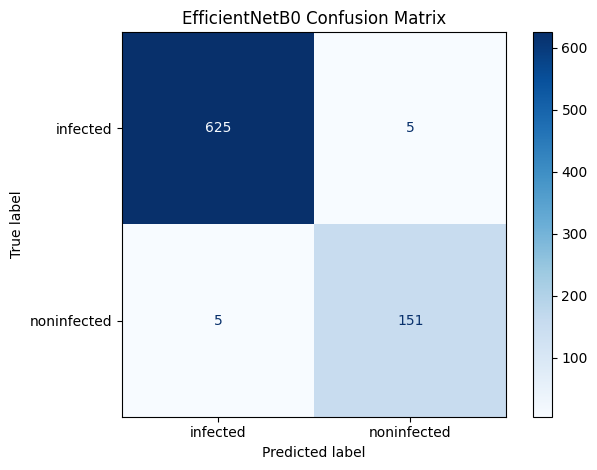

Confusion matrix saved.


In [20]:
plt.figure(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["infected", "noninfected"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("EfficientNetB0 Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/PCOS_Project/efficientnetb0_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved.")

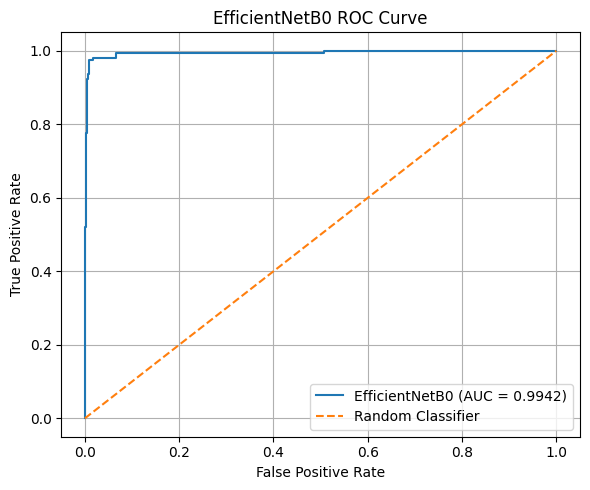

ROC curve saved.


In [21]:
#ROC Curve
fpr, tpr, thresholds = roc_curve(
    all_labels,
    all_probabilities
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"EfficientNetB0 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EfficientNetB0 ROC Curve")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/PCOS_Project/efficientnetb0_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved.")

In [22]:
import os
import shutil

results_dir = "/content/drive/MyDrive/PCOS_Project/EFFICIENTNETB0_RESULTS"

os.makedirs(results_dir, exist_ok=True)

shutil.copy(
    "/content/drive/MyDrive/PCOS_Project/efficientnetb0_confusion_matrix.png",
    os.path.join(results_dir, "confusion_matrix.png")
)

shutil.copy(
    "/content/drive/MyDrive/PCOS_Project/efficientnetb0_roc_curve.png",
    os.path.join(results_dir, "roc_curve.png")
)

print("EfficientNetB0 result files saved:")
print(os.listdir(results_dir))

EfficientNetB0 result files saved:
['confusion_matrix.png', 'roc_curve.png']
